# US Accidents: learning to predict traffic impact

**Group:** Yanis Barbieux, Kamar Benbacha, Théophile Melquiot

**Hands-on Machine Learning, M1 Computer Science**

### AI use disclosure

AI tools were used to help write and revise the documentation and Markdown,
format the notebook, define and clarify variables, and write code.

## 1. Introduction

Can the context of an accident help us identify a high impact on traffic?
Our target is **Severity 3 or 4 versus Severity 1 or 2**. It describes traffic
disruption, rather than injuries or the risk that an accident will occur.

We developed separate approaches and brought them together. Kamar explored
the columns and missing values, prepared a larger sample, and compared
logistic regression with two tree models. Yanis focused on time-based
evaluation, repeated events and boosting with native categorical features.
Their differences gave us concrete questions: which records should we keep,
how should we encode categories, and does a larger sample help?

This notebook develops the common approach step by step. We use Source2,
compare boosting with a random forest and a logistic regression reference,
and explain the choices supported by validation. Weather is examined both at accident start and in an update
allowing an observation up to one hour later.

Dataset: [US Accidents, March 2023 version](https://www.kaggle.com/datasets/sobhanmoosavi/us-accidents).
Severity definition: [creator metadata](https://www.kaggle.com/sobhanmoosavi/us-accidents/metadata).

### Related work and our contribution

Moosavi et al., [A Countrywide Traffic Accident Dataset (2019)](https://arxiv.org/abs/1906.05409),
introduced US-Accidents with time, location, weather and nearby points of
interest. Its original release is smaller than the March 2023 file we use.
Their [Accident Risk Prediction based on Heterogeneous Sparse Data (2019)](https://arxiv.org/abs/1909.09638)
describes a deep learning approach to predicting accident occurrence, which
differs from predicting the traffic impact of an already recorded accident.
These points come from the abstracts; we have not read the full articles and
do not compare their scores with ours.

Many public notebooks also predict severity on this dataset. We have not
reviewed them systematically, so we cite none of their scores. We suspect
that some very high public results rely on random splits or on fields
recorded after the accident, such as its end time, distance or description.
This is a hypothesis we have not demonstrated, not a finding.

We do not expect to beat a published score; our contribution lies in the
method. We evaluate in chronological order, because the labels drift
between sources and years. We check which information is available at
prediction time, especially weather timestamps. We measure which groups of
inputs the model relies on, and we use metrics suited to an imbalanced
target. We use existing algorithms and focus on understanding what the data
and the results allow us to conclude.

## 2. Preprocessing

### 2.1 Set up one common configuration

We keep the main choices together so the study is easy to reproduce. The CSV
is kept locally and is not part of the submission. Install
`requirements-final-notebook.txt` and open the notebook within the project.
Python modules handle reusable data access; the main transformations and
model training remain visible below.

In [1]:
import os
for name in ["OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"]:
    os.environ[name] = "4"
from pathlib import Path
import sys, json, itertools, gc, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, HTML
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.inspection import permutation_importance
from sklearn.metrics import (average_precision_score, roc_auc_score,
    precision_recall_curve, precision_score, recall_score, f1_score, confusion_matrix)
from threadpoolctl import threadpool_limits

ROOT = Path.cwd().resolve()
if (ROOT / "us_accidents_traffic_impact_prediction/traffic_impact").is_dir():
    ROOT = ROOT / "us_accidents_traffic_impact_prediction"
while not (ROOT / "traffic_impact").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
assert (ROOT / "traffic_impact").is_dir(), "Open this notebook inside the project."
sys.path.insert(0, str(ROOT))
from traffic_impact.final_notebook import find_csv, load_samples, data_dictionary, nearby_keys
from traffic_impact.experiment import POI, LIGHT, WNUM, WCAT, FORBIDDEN, preprocessor
CSV_PATH = find_csv()  # Change this path if the CSV is stored elsewhere.
WORK = ROOT / "data/final_notebook"
REPORTS, FIGURES = WORK / "reports", WORK / "figures"
for path in [REPORTS, FIGURES]:
    path.mkdir(parents=True, exist_ok=True)
SEED, TRAIN_N, WEATHER_AFTER, WEATHER_CAP = 42, 500_000, 60, 25
COMPARISONS = ROOT / "results/final_notebook_comparison"
pd.set_option("display.max_columns", 9)
plt.rcParams.update({"figure.figsize": (8, 3.6), "figure.dpi": 100})
display(pd.Series({"Training events": TRAIN_N, "Weather update (minutes)": WEATHER_AFTER,
    "Weather category limit": WEATHER_CAP, "Seed": SEED}, name="Common choices").to_frame())

,Common choices
Training events,500000
Weather update (minutes),60
Weather category limit,25
Seed,42


The configuration uses a fixed seed and keeps the natural class proportions.
Time and location always refer to the accident start; only the weather window
changes between the two scenarios.

### 2.2 Look at the original records

Kamar began by reading a small part of the file before loading larger samples.
We keep this useful first step: identify the columns and their units, then
inspect a few records. The first rows illustrate the format; they are not a
representative sample for drawing conclusions.

In [2]:
preview = pd.read_csv(CSV_PATH, nrows=5)
dictionary = data_dictionary(preview.columns)
dictionary.to_csv(REPORTS / "data_dictionary.csv", index=False)
display(preview[["Source", "Severity", "Start_Time", "State", "Temperature(F)",
                 "Weather_Timestamp"]])
ROAD = [c for c in POI if c != "Turning_Loop"]
input_groups = pd.DataFrame({
    "Group": ["Time", "Location", "Road context", "Light", "Weather"],
    "Inputs": [4, 4, len(ROAD), len(LIGHT), len(WNUM) + len(WCAT)],
    "Examples": ["hour, weekday, month, weekend", "latitude, longitude, State, Timezone",
                 "junction, crossing, signals", "day/night and twilight",
                 "temperature, visibility, wind, conditions"]})
display(input_groups)

,Source,Severity,Start_Time,State,Temperature(F),Weather_Timestamp
0,Source2,3,2016-02-08 05:46:00,OH,36.9,2016-02-08 05:58:00
1,Source2,2,2016-02-08 06:07:59,OH,37.9,2016-02-08 05:51:00
2,Source2,2,2016-02-08 06:49:27,OH,36.0,2016-02-08 06:56:00
3,Source2,3,2016-02-08 07:23:34,OH,35.1,2016-02-08 07:38:00
4,Source2,2,2016-02-08 07:39:07,OH,36.0,2016-02-08 07:53:00


,Group,Inputs,Examples
0,Time,4,"hour, weekday, month, weekend"
1,Location,4,"latitude, longitude, State, Timezone"
2,Road context,12,"junction, crossing, signals"
3,Light,4,day/night and twilight
4,Weather,9,"temperature, visibility, wind, conditions"


The file mixes numerical measurements, categories, flags and timestamps.
Units such as Fahrenheit, miles and inches are kept as recorded. The five
groups give 33 logical inputs. The road group leaves out Turning_Loop, which
is always False in the audited file. The complete dictionary in the appendix
defines every original column, including fields we exclude, and the four
derived time variables.

### 2.3 Work with distinct events

We read the full file in blocks when samples must be prepared. Uniform event
priorities with seed 42 select distinct Source2 events within each period.
Priorities do not depend on Severity. The 200,000-event sample will be a
subset of the 500,000-event sample.

An event key uses Source, start/end time, start coordinates, Distance and
Description, without Severity. Repeated copies are grouped; events with
conflicting Severity labels are excluded, even if their binary labels agree.
Some identity fields are excluded from prediction. Nearby accidents are not
automatically treated as the same event.

In [3]:
raw, audit, AUDIT_FOLDER = load_samples(CSV_PATH, WORK)
raw["train"] = raw["train"].nsmallest(TRAIN_N, "_priority").sort_values("_t").reset_index(drop=True)
audit_summary = pd.Series({"Original records": audit["rows"],
    "Original columns": audit["columns"], "Source2 records": audit["source2_rows"],
    "Repeated Source2 event records": audit["source2_duplicate_event_rows"],
    "Conflicting Source2 event keys": audit["source2_conflicting_event_keys"]}, name="Full-file audit")
display(audit_summary.to_frame())

,Full-file audit
Original records,7728394
Original columns,46
Source2 records,3305373
Repeated Source2 event records,2136
Conflicting Source2 event keys,8


The full-file audit distinguishes repeated events from record identifiers.
All copies of a conflicting event are excluded because the file does not
tell us which label is correct. Sampling keeps the study manageable without
forcing the two classes to have equal sizes. Verified caches are reused when
the CSV, preparation code, environment and file hashes match.

### 2.4 Compare sources before choosing the study population

Both individual approaches examined the providers. We plot the proportion
of positive labels by source and year, using the full-file audit. This helps
us decide whether mixing sources would make the target difficult to interpret.

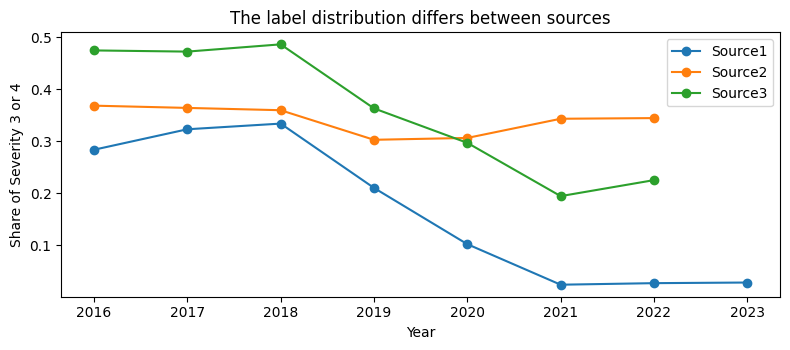

In [4]:
source_month = pd.read_csv(AUDIT_FOLDER / "monthly_source_severity.csv")
source_month["year"] = pd.to_numeric(source_month["_month"].str[:4], errors="coerce")
source_month["positives"] = source_month["count"].where(source_month.Severity.ge(3), 0)
source_year = source_month.groupby(["Source", "year"])[["count", "positives"]].sum()
source_year["positive_rate"] = source_year.positives / source_year["count"]
for source, group in source_year.reset_index().groupby("Source"):
    plt.plot(group.year, group.positive_rate, marker="o", label=source)
plt.xlabel("Year")
plt.ylabel("Share of Severity 3 or 4")
plt.title("The label distribution differs between sources")
plt.legend()
plt.tight_layout()
plt.savefig(FIGURES / "01_sources.png")
plt.show()

The sources have different label distributions and changes over time.
We focus on Source2 to give the study a clear scope. This does not establish
the cause of changes in other sources, or prove that Source2 is always better.
Source2 ends in September 2022, so our last period is incomplete.

### 2.5 Clean invalid values without deleting incomplete weather records

Kamar removed rows with more than four missing predictors, then filled the
remaining gaps using training statistics. For the common study, we keep
records without weather: their time, location and road context remain useful.
This avoids selecting only accidents whose weather is better documented.

A valid date and a label in 1-4 are required. Impossible coordinates, humidity
or negative physical measurements become missing; plausible extremes remain.
We do not impute the target. Temperature has no arbitrary cutoff.

In [5]:
raw_clean, cleaning_rows, invalid_rows = {}, [], []
bounds = {"Start_Lat": (-90, 90), "Start_Lng": (-180, 180), "Humidity(%)": (0, 100),
    "Pressure(in)": (0, np.inf), "Visibility(mi)": (0, np.inf),
    "Wind_Speed(mph)": (0, np.inf), "Precipitation(in)": (0, np.inf)}
for split, original in raw.items():
    frame = original.copy()
    frame["_t"] = pd.to_datetime(frame.Start_Time, format="mixed", errors="coerce")
    valid = frame._t.notna() & frame.Severity.isin([1, 2, 3, 4])
    cleaning_rows.append({"Period": split, "Before": len(frame),
        "Invalid date/label": int((~valid).sum()), "After": int(valid.sum())})
    frame = frame.loc[valid].reset_index(drop=True)
    for column, (lower, upper) in bounds.items():
        values = pd.to_numeric(frame[column], errors="coerce")
        bad = values.notna() & (~values.between(lower, upper) | ~np.isfinite(values))
        invalid_rows.append({"split": split, "column": column, "changed": int(bad.sum())})
        frame[column] = values.mask(bad)
    raw_clean[split] = frame
cleaning = pd.DataFrame(cleaning_rows)
invalid = pd.DataFrame(invalid_rows)
display(cleaning)
display(invalid.groupby("column").changed.sum().rename("Invalid values replaced").to_frame())
cleaning.to_csv(REPORTS / "record_cleaning.csv", index=False)
invalid.to_csv(REPORTS / "numeric_cleaning.csv", index=False)

,Period,Before,Invalid date/label,After
0,train,500000,0,500000
1,validation,50000,0,50000
2,test,99999,0,99999
3,stress,50000,0,50000


,Invalid values replaced
column,
Humidity(%),0
Precipitation(in),0
Pressure(in),0
Start_Lat,0
Start_Lng,0
Visibility(mi),0
Wind_Speed(mph),0


These samples contain no invalid dates, labels or values under the specified
physical bounds, so this cleaning step keeps their records unchanged. This
does not guarantee that the entire file is error-free. Keeping incomplete weather is a
choice about the population studied, not a measured victory over Kamar's
row-removal policy.

### 2.6 Keep the evaluation in chronological order

Kamar used full evaluation years with boundaries in September; Yanis used
calendar years. The common study keeps calendar years for clarity. We learn
on 2016-2019, compare settings on 2020, and examine 2021 and the available
part of 2022 afterwards. Labels remain separate from predictors.

,Period,Events,Positive share (%),First date,Last date
0,2016-2019 (train),500000,34.4,2016-02-08,2019-12-31
1,2020 (validation),50000,30.3,2020-01-01,2020-12-31
2,2021 (historical),99999,34.3,2021-01-01,2021-12-31
3,2022 to Sep 8,50000,34.7,2022-01-01,2022-09-08


The positive share is **34.4%** in 2016-2019, **30.3%** in 2020, **34.3%** in 2021 and **34.7%** in the available part of 2022.

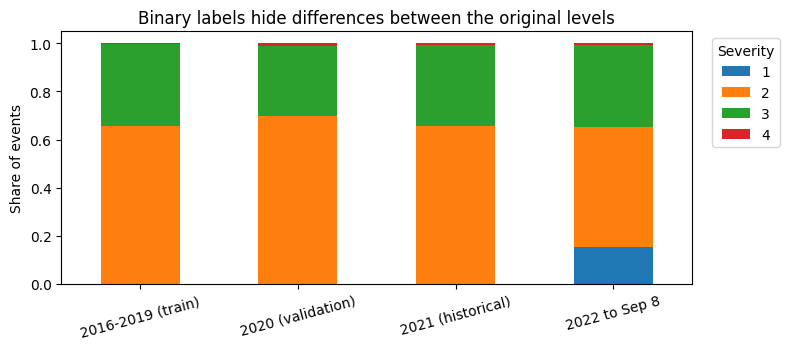

In [6]:
period_names = {"train": "2016-2019 (train)", "validation": "2020 (validation)",
    "test": "2021 (historical)", "stress": "2022 to Sep 8"}
y = {s: d.Severity.ge(3).to_numpy(dtype="int8") for s, d in raw_clean.items()}
sample_table = pd.DataFrame([{"Period": period_names[s], "Events": len(d),
    "Positive share (%)": round(100 * y[s].mean(), 1),
    "First date": str(d._t.min().date()), "Last date": str(d._t.max().date())}
    for s, d in raw_clean.items()])
display(sample_table)
shares = {s: 100 * y[s].mean() for s in y}
display(Markdown(f"The positive share is **{shares['train']:.1f}%** in 2016-2019, "
    f"**{shares['validation']:.1f}%** in 2020, **{shares['test']:.1f}%** in 2021 "
    f"and **{shares['stress']:.1f}%** in the available part of 2022."))
levels = pd.DataFrame({period_names[s]: d.Severity.value_counts().reindex([1, 2, 3, 4], fill_value=0)
    for s, d in raw_clean.items()}).T
levels.div(levels.sum(axis=1), axis=0).plot.bar(stacked=True, figsize=(8, 3.6))
plt.ylabel("Share of events")
plt.xlabel("")
plt.xticks(rotation=15)
plt.legend(title="Severity", bbox_to_anchor=(1.02, 1))
plt.title("Binary labels hide differences between the original levels")
plt.tight_layout()
plt.savefig(FIGURES / "02_levels.png")
plt.show()

Around one third of the sampled accidents belong to the positive class, so
accuracy alone would be insufficient. Most positive records are Severity 3;
Severity 4 is rare. The share of Severity 1 also changes in 2022. Later-year
results must be read with these population differences in mind. The project
has already examined 2021 and 2022; these are historical evaluations, not new
independent tests.

2020, our validation year, is less positive than the training years and the
two later years. The COVID-19 period may have changed traffic and recording,
but this is a hypothesis we have not demonstrated. The difference matters in
two ways. AP and ROC-AUC measure how well a model ranks accidents, so they
remain comparable in spirit across years, although AP also depends on the
positive share. The F1 threshold, however, is fixed on 2020 and then applied
to more positive years, where it is not re-optimised. 2022 also stops on
8 September, so it covers only part of a year. 2021 is therefore our complete
reference year for evaluation.

### 2.7 Derive features that describe the accident context

Following the individual notebooks, we turn Start_Time into hour, weekday,
month and a weekend flag. We keep start location, nearby road features and
the light indicators. End time, end coordinates, Distance and Description
are excluded because their initial availability is not established.

,hour,day_of_week,month,weekend
0,8,0,2,0
1,9,0,2,0
2,12,0,2,0
3,15,0,2,0
4,20,0,2,0


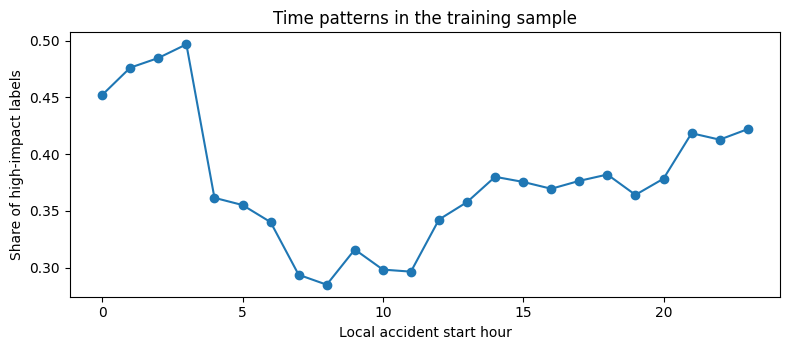

In [7]:
def initial_features(frame):
    time = frame["_t"]
    result = pd.DataFrame({"hour": time.dt.hour, "day_of_week": time.dt.dayofweek,
        "month": time.dt.month, "weekend": time.dt.dayofweek.ge(5).astype(int)})
    for column in ["Start_Lat", "Start_Lng", "State", "Timezone"] + POI + LIGHT + WNUM + WCAT:
        result[column] = frame[column]
    for column in POI:
        result[column] = result[column].astype(float)
    for column in ["State", "Timezone"] + LIGHT + WCAT:
        result[column] = result[column].astype("string")
    return result

initial = {s: initial_features(d) for s, d in raw_clean.items()}
display(initial["train"][["hour", "day_of_week", "month", "weekend"]].head())
by_hour = pd.Series(y["train"]).groupby(initial["train"].hour).mean()
by_hour.plot(marker="o")
plt.xlabel("Local accident start hour")
plt.ylabel("Share of high-impact labels")
plt.title("Time patterns in the training sample")
plt.tight_layout()
plt.savefig(FIGURES / "03_hour.png")
plt.show()

The curve describes an association in the training data, not a causal effect
of the hour. We do not include the year as a predictor. Turning_Loop is
always False in the audited file, so it cannot provide any signal; it is
excluded from the 33 inputs in 2.12. Day/night indicators describe natural
light at the start, not artificial road lighting.

### 2.8 Clarify the two weather scenarios with an example

The file contains one weather observation already associated with each
accident. We check its timestamp; we cannot retrieve a different reading.
Kamar accepted observations within two hours before or after the start.
Yanis initially accepted only the two preceding hours. We compare that strict
rule with an update allowing up to one hour after the start.

In [8]:
example = pd.DataFrame({"Accident start": ["10:00"] * 5,
    "Associated observation": ["07:59", "08:00", "09:30", "10:30", "11:01"],
    "Offset (minutes)": [-121, -120, -30, 30, 61]})
example["At start"] = example["Offset (minutes)"].between(-120, 0)
example["With update"] = example["Offset (minutes)"].between(-120, 60)
display(example)

,Accident start,Associated observation,Offset (minutes),At start,With update
0,10:00,07:59,-121,False,False
1,10:00,08:00,-120,True,True
2,10:00,09:30,-30,True,True
3,10:00,10:30,30,False,True
4,10:00,11:01,61,False,False


This is an illustrative example, not five sampled accidents. A 10:30
observation cannot be used for a prediction at 10:00. The update is a later
prediction; even an eligible timestamp does not establish when the reading
was published. Other future fields do not receive this weather exception.

### 2.9 Apply the weather rule and harmonise wind labels

All nine weather fields are masked together if the timestamp is missing or
outside the chosen window. The accident remains. We also merge spelling
variants such as East/E, without merging different directions such as NE/NW.

In [9]:
aliases = {"NORTH": "N", "SOUTH": "S", "EAST": "E", "WEST": "W",
    "CALM": "Calm", "VAR": "Variable", "VARIABLE": "Variable"}
def weather_features(frame, after=60):
    result = initial_features(frame)
    observed = pd.to_datetime(frame.Weather_Timestamp, format="mixed", errors="coerce")
    offset = (observed - frame["_t"]).dt.total_seconds() / 60
    eligible = offset.between(-120, after)
    for column in WNUM:
        result[column] = pd.to_numeric(result[column], errors="coerce").where(eligible)
    for column in WCAT:
        values = result[column]
        if column == "Wind_Direction":
            values = values.str.strip().str.upper().replace(aliases)
        result[column] = values.where(eligible)
    return result, eligible

features, weather_rows = {}, []
for split, frame in raw_clean.items():
    features[split], _ = weather_features(frame, WEATHER_AFTER)
    for after, scenario in [(0, "At start"), (WEATHER_AFTER, "With update")]:
        _, eligible = weather_features(frame, after)
        weather_rows.append({"Period": period_names[split], "Scenario": scenario,
            "Eligible timestamps (%)": round(100 * eligible.mean(), 1)})
weather_table = pd.DataFrame(weather_rows)
display(weather_table[weather_table.Period.eq(period_names["validation"])])
weather_table.to_csv(REPORTS / "weather_coverage.csv", index=False)

,Period,Scenario,Eligible timestamps (%)
2,2020 (validation),At start,50.4
3,2020 (validation),With update,97.9


The wider window keeps substantially more associated observations. Timestamp
eligibility is not the same as complete weather: individual fields can still
be missing. We retain the update as the main scenario and keep the strict rule
as a comparison, with its different prediction time clearly stated.

### 2.10 Inspect missing values before deciding how to handle them

Kamar's missingness analysis showed why removing every incomplete row would
discard too much data. Here we compare the same training events before and
after timestamp masking. The masking can increase missingness without deleting
records. Boosting can retain numerical gaps; the forest and the logistic
regression need complete values.

,Before timestamp rule (%),After timestamp rule (%)
Temperature(F),1.7,2.6
Wind_Chill(F),64.1,64.3
Humidity(%),1.8,2.7
Pressure(in),1.5,2.4
Visibility(mi),2.0,3.0
Wind_Speed(mph),15.2,15.9
Precipitation(in),68.5,68.6
Wind_Direction,1.4,2.3
Weather_Condition,2.0,3.0


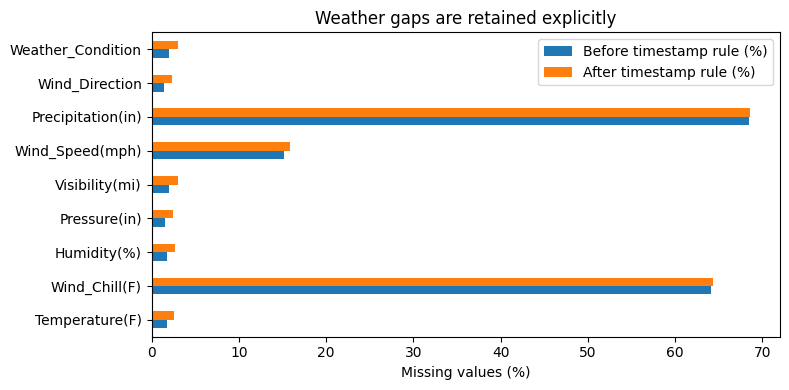

In [10]:
missingness = pd.DataFrame({"Before timestamp rule (%)": initial["train"].isna().mean() * 100,
    "After timestamp rule (%)": features["train"].isna().mean() * 100})
missingness = missingness.loc[WNUM + WCAT].round(1)
display(missingness)
missingness.plot.barh(figsize=(8, 4))
plt.xlabel("Missing values (%)")
plt.ylabel("")
plt.title("Weather gaps are retained explicitly")
plt.tight_layout()
plt.savefig(FIGURES / "04_missingness.png")
plt.show()
missingness.to_csv(REPORTS / "missingness_before_after.csv")

Precipitation and wind chill have the most missing values in the training
sample, even before timestamp masking. Missing weather does not erase the other
context. Each model uses an appropriate representation of absence. This does
not show that missingness itself causes higher or lower traffic impact.

### 2.11 Prepare a temperature fill for missing wind chill

The US National Weather Service wind chill formula is only defined for a
temperature of at most 50 °F and a wind of at least 3 mph. Otherwise, the
felt temperature is simply the air temperature. A missing wind chill
therefore often means "same as the temperature", not "unknown". Its missing
share also drifts strongly over time, as the table below shows.

For the forest and the logistic regression only, we prepare a version where
a missing Wind_Chill(F) takes Temperature(F) from the same row. This happens
after the weather rule of 2.9, so a masked observation stays masked. The
training median is applied afterwards, only when the temperature is missing
too. Boosting keeps its native missing values.

In [11]:
def fill_wind_chill(frame):
    result = frame.copy()
    result["Wind_Chill(F)"] = result["Wind_Chill(F)"].fillna(result["Temperature(F)"])
    return result

filled = {s: fill_wind_chill(frame) for s, frame in features.items()}
wind_chill = pd.concat([pd.DataFrame({"Year": raw_clean[s]._t.dt.year,
    "Recorded missing (%)": initial[s]["Wind_Chill(F)"].isna(),
    "After weather rule (%)": features[s]["Wind_Chill(F)"].isna(),
    "After temperature fill (%)": filled[s]["Wind_Chill(F)"].isna()}) for s in features])
wind_chill_table = (100 * wind_chill.groupby("Year").mean()).round(1)
display(wind_chill_table)
wind_chill_table.to_csv(REPORTS / "wind_chill_missing_by_year.csv")
train_weather = features["train"]
temperature, chill = train_weather["Temperature(F)"], train_weather["Wind_Chill(F)"]
outside_formula = (chill.notna() & temperature.notna() & train_weather["Wind_Speed(mph)"].notna()
    & (temperature.gt(50) | train_weather["Wind_Speed(mph)"].lt(3)))
same = (chill[outside_formula] - temperature[outside_formula]).abs().le(0.5).mean()
display(Markdown(f"Recorded wind chill is missing for **{wind_chill_table.loc[2016].iloc[0]:.1f}%** "
    f"of sampled 2016 accidents and **{wind_chill_table.loc[2020].iloc[0]:.1f}%** in 2020. "
    f"In training, where both values are recorded outside the formula's domain, wind chill "
    f"equals the temperature (within 0.5 °F) for **{100 * same:.1f}%** of accidents."))

,Recorded missing (%),After weather rule (%),After temperature fill (%)
Year,,,
2016,90.7,90.8,2.7
2017,85.5,85.5,2.8
2018,82.0,82.1,2.9
2019,17.0,17.5,2.1
2020,2.4,3.2,2.5
2021,2.0,3.0,2.5
2022,2.4,3.3,2.7


Recorded wind chill is missing for **90.7%** of sampled 2016 accidents and **2.4%** in 2020. In training, where both values are recorded outside the formula's domain, wind chill equals the temperature (within 0.5 °F) for **100.0%** of accidents.

Outside the formula's domain, the recorded values confirm the rule. After
the fill, the remaining missing share is small and much more stable across
years, so far fewer accidents would receive the single training median.
That median is not a leak either: it is computed on 2016-2019 only. The fill
uses another field of the same accident, so no later information enters.
Whether the fill helps prediction is a separate question: we compare both
options on 2020 with the forest in 3.4 and keep the better one.

### 2.12 Learn categorical vocabularies on training data only

We keep Kamar's idea of grouping rare weather conditions into Other. A category
needs at least 100 training occurrences; Weather_Condition keeps at most the
25 most frequent eligible labels. Missing is separate from Other. Later data
cannot change the vocabulary. Numerical and road inputs use compact types.

In [12]:
class CategoryPreparation:
    def __init__(self, weather_cap=25):
        self.weather_cap = weather_cap

    def fit(self, frame):
        self.columns = [c for c in frame if frame[c].nunique(dropna=False) > 1]
        self.vocab = {}
        for column in self.columns:
            if pd.api.types.is_string_dtype(frame[column].dtype):
                counts = frame[column].value_counts()
                keep = counts[counts >= 100].index.tolist()
                if column == "Weather_Condition":
                    keep = keep[:self.weather_cap]
                self.vocab[column] = [str(v) for v in keep if v not in ["Missing", "Other"]]
        return self

    def transform(self, frame):
        result = frame[self.columns].copy()
        for column, vocabulary in self.vocab.items():
            values = result[column].fillna("Missing").astype(str)
            values = values.where(values.isin(vocabulary + ["Missing"]), "Other")
            result[column] = pd.Categorical(values, categories=vocabulary + ["Missing", "Other"])
        for column in self.columns:
            if column not in self.vocab:
                result[column] = result[column].astype("float32")
        return result

category_prep = CategoryPreparation(WEATHER_CAP).fit(features["train"])
X = {s: category_prep.transform(frame) for s, frame in features.items()}
display(pd.DataFrame([{"Feature": c, "Retained training labels": len(v),
    "Missing label": "Missing", "Rare/unseen label": "Other"} for c, v in category_prep.vocab.items()]))

,Feature,Retained training labels,Missing label,Rare/unseen label
0,State,40,Missing,Other
1,Timezone,4,Missing,Other
2,Sunrise_Sunset,2,Missing,Other
3,Civil_Twilight,2,Missing,Other
4,Nautical_Twilight,2,Missing,Other
5,Astronomical_Twilight,2,Missing,Other
6,Wind_Direction,18,Missing,Other
7,Weather_Condition,25,Missing,Other


The vocabulary has been learned once, then reused for all periods. The native
categorical dtype tells boosting that categories have no numerical order.
Columns that are constant in training are dropped, which removes Turning_Loop
and leaves 33 logical inputs. We have not demonstrated that each of them is
necessary.

### 2.13 Make the transformations concrete

We inspect a few real category transformations and a small one-hot example.
One-hot creates an indicator for each category: it avoids inventing an order
between states, but increases the number of columns. We adapt the preparation
to each model rather than assuming one representation is always best.

In [13]:
transformed = pd.DataFrame({"Recorded wind": raw_clean["train"].Wind_Direction.astype("string"),
    "After weather/spelling rule": features["train"].Wind_Direction,
    "Final wind category": X["train"].Wind_Direction.astype("string")})
display(transformed.drop_duplicates().head(8).fillna("<missing>"))
display(pd.get_dummies(pd.DataFrame({"State": ["CA", "NY", "TX"]}), dtype=int))
transformation_summary = pd.DataFrame([{"Step": "Start_Time to four time inputs", "Output": "hour, weekday, month, weekend"},
    {"Step": "Boolean road indicators", "Output": "0/1"},
    {"Step": "Weather outside window", "Output": "Missing weather; accident kept"},
    {"Step": "Rare or new categorical value", "Output": "Other"},
    {"Step": "Missing categorical value", "Output": "Missing"}])
display(transformation_summary)

,Recorded wind,After weather/spelling rule,Final wind category
0,WNW,WNW,WNW
1,WSW,WSW,WSW
2,West,W,W
3,NNE,NNE,NNE
6,SW,SW,SW
20,NW,NW,NW
21,SSW,SSW,SSW
23,Variable,Variable,Variable


,State_CA,State_NY,State_TX
0,1,0,0
1,0,1,0
2,0,0,1


,Step,Output
0,Start_Time to four time inputs,"hour, weekday, month, weekend"
1,Boolean road indicators,0/1
2,Weather outside window,Missing weather; accident kept
3,Rare or new categorical value,Other
4,Missing categorical value,Missing


The wind table shows observed transformations. The three-state table is a
teaching example. One-hot does not add new observations or fill weather gaps.
We use native categories for boosting and one-hot for the forest and the
logistic regression. The study
does not directly compare these two encodings with the same boosting model.

## 3. Training



### 3.1 Check model capacity, then training volume

Boosting builds trees one after another, each correcting the errors of the
previous ones. A larger leaf limit lets each tree distinguish more
combinations of conditions. More iterations add correction steps, but both
choices can lead to fitting training details too closely. We fit three
settings on 2016-2019 and compare their AP on 2020. All other parameters are
those of the main model, and the 63-leaf, 400-iteration model is the main
model itself, reused in the rest of the notebook.

In [14]:
boosting_settings = {"max_iter": 400, "max_leaf_nodes": 63, "learning_rate": 0.1,
    "categorical_features": "from_dtype", "early_stopping": False, "random_state": SEED}
boosting = HistGradientBoostingClassifier(**boosting_settings)
capacity_rows = []
with threadpool_limits(limits=4):
    for leaves, iterations in [(31, 200), (63, 200), (63, 400)]:
        settings = {**boosting_settings, "max_leaf_nodes": leaves, "max_iter": iterations}
        model = boosting if settings == boosting_settings else HistGradientBoostingClassifier(**settings)
        start = time.perf_counter()
        model.fit(X["train"], y["train"])
        fit_seconds = time.perf_counter() - start
        capacity_rows.append({"Maximum leaves": leaves, "Iterations": iterations,
            "Validation AP": average_precision_score(y["validation"], model.predict_proba(X["validation"])[:, 1]),
            "Fit seconds": fit_seconds})
del model
capacity = pd.DataFrame(capacity_rows)
display(capacity.round({"Validation AP": 3, "Fit seconds": 0}))
capacity.to_csv(REPORTS / "boosting_capacity.csv", index=False)
validation_trials = pd.read_csv(COMPARISONS / "validation.csv")
volume_names = ["e19_hgb_200000_w60_c25_refined", "e21_hgb_500000_w60_c25_refined"]
volume = validation_trials.set_index("name").loc[volume_names, ["train_n", "ap"]]
display(volume.rename(columns={"train_n": "Training events", "ap": "Validation AP"}).reset_index(drop=True).round(3))

,Maximum leaves,Iterations,Validation AP,Fit seconds
0,31,200,0.715,10.0
1,63,200,0.735,12.0
2,63,400,0.748,20.0


,Training events,Validation AP
0,200000,0.729
1,500000,0.748


The capacity table is computed in this execution. It supports 63 leaves per
tree and 400 iterations, at a higher training cost. The volume table is
different: it reports results recorded in our earlier common comparisons,
not recomputed here. With the selected settings, the larger sample improved
validation AP, so we retain 500,000 events. We learn from changing one aspect
while keeping the comparison conditions clear; the results do not establish
a universal optimum.

### 3.2 Refine the weather grouping and check the prediction-time tradeoff

The number of frequent Weather_Condition labels is a separate preparation
choice. We also compare the strict and updated weather scenarios at the
reference model settings. Each question has a small table, with one metric
and no execution log. Both tables report results recorded in our earlier
common comparisons; they are not recomputed in this notebook.

In [15]:
category_names = ["e20_hgb_500000_w60_c10_refined", "e12_hgb_500000_w60_c15", "e21_hgb_500000_w60_c25_refined"]
categories = validation_trials.set_index("name").loc[category_names, ["cap", "ap"]]
display(categories.rename(columns={"cap": "Weather category limit", "ap": "Validation AP"}).reset_index(drop=True).round(3))
weather_comparison = validation_trials.set_index("name").loc[
    ["e05_hgb_500000_w0_c15", "e07_hgb_500000_w60_c15"], ["after", "ap"]].copy()
weather_comparison.index = ["At start", "With update"]
display(weather_comparison.rename(columns={"after": "Minutes after start allowed", "ap": "Validation AP"}).round(3))

,Weather category limit,Validation AP
0,10,0.747
1,15,0.746
2,25,0.748


,Minutes after start allowed,Validation AP
At start,0,0.705
With update,60,0.713


The limit of 25 has the highest AP among the three grouping limits, but the
differences are small: this is a modest refinement. The weather update gives
a modest improvement at the reference settings and much greater timestamp
coverage. This gain was not measured again with the final tuned settings.
The update also requires a different prediction time from the strict scenario.

### 3.3 Describe the main boosting model

Our main model is scikit-learn's `HistGradientBoostingClassifier`.
Boosting builds trees sequentially using the gradient of the loss. Numerical
bins make its split search efficient; categorical inputs are handled natively.
The selected configuration was already trained on 2016-2019 in 3.1; we reuse
it without refitting. There is no class weighting, synthetic balancing or
random early-stopping split.

In [16]:
prior = float(y["train"].mean())
display(pd.Series({"Training events": len(y["train"]), "Logical inputs": X["train"].shape[1],
    "Maximum leaves per tree": boosting.max_leaf_nodes, "Iterations": boosting.n_iter_}, name="Boosting").to_frame())

,Boosting
Training events,500000
Logical inputs,33
Maximum leaves per tree,63
Iterations,400


The model uses the larger sample and the selected tree capacity. The constant
baseline assigns the training positive share to every accident; it will help
us judge how much the context improves ranking.

#### 3.3.1 LightGBM as an alternative boosting implementation

We also trained LightGBM's `LGBMClassifier` to check whether another
gradient boosting implementation offers a useful alternative. The comparison
reuses the same 500,000 training events, 33 inputs, native categories and
chronological splits. Key settings are matched: 400 trees, at most 63 leaves
per tree and a learning rate of 0.1, with no early stopping. These settings
provide comparable capacity without making the algorithms identical.

The table summarises the earlier experiment in
[compare_lightgbm.py](../scripts/compare_lightgbm.py), using its
[recorded scores](../results/lightgbm_comparison/scores.csv) and
[timings](../results/lightgbm_comparison/summary.json).

| Model | Validation AP (2020) | Fit time (seconds) |
| --- | ---: | ---: |
| HistGradientBoosting (main model) | 0.7477 | 36.4 |
| LightGBM | 0.7446 | 12.1 |

LightGBM achieves a close validation AP with faster training in this run.
We retain the main model with its slightly higher validation AP and keep
LightGBM as a supplementary comparison. The small AP gap and this single
timing measurement do not establish a general ranking.

### 3.4 Fit a forest with its own preparation

A random forest averages trees fitted on bootstrap samples, with random
feature subsets at each split. We keep 100 trees and at least five events per
leaf, as selected on the common validation. Numerical gaps receive training
medians and categories receive one-hot indicators. The selected forest uses
a weather limit of 15, while boosting uses 25; each keeps its validated setup.
We fit the forest twice, with and without the wind chill fill of 2.11, and
keep the option with the higher AP on 2020.

In [17]:
forest_categories = CategoryPreparation(weather_cap=15).fit(features["train"])

def fit_forest(inputs):
    train = forest_categories.transform(inputs["train"])
    pre = preprocessor(train)
    matrix = pre.fit_transform(train).astype("float32").toarray()
    model = RandomForestClassifier(n_estimators=100, min_samples_leaf=5,
        max_features="sqrt", random_state=SEED, n_jobs=4)
    with threadpool_limits(limits=4):
        model.fit(matrix, y["train"])
        encoded = pre.transform(forest_categories.transform(inputs["validation"]))
        ap = average_precision_score(y["validation"], model.predict_proba(encoded.astype("float32").toarray())[:, 1])
    return {"model": model, "pre": pre, "ap": ap, "columns": matrix.shape[1]}

wind_chill_options = {"Training median": features, "Temperature, then training median": filled}
forest_fits = {}
for option, inputs in wind_chill_options.items():
    forest_fits[option] = fit_forest(inputs)
    _ = gc.collect()
wind_chill_choice = pd.DataFrame({"Missing Wind_Chill(F)": list(forest_fits),
    "Forest validation AP": [fit["ap"] for fit in forest_fits.values()]})
display(wind_chill_choice.round(4))
wind_chill_choice.to_csv(REPORTS / "wind_chill_choice.csv", index=False)
wind_chill_option = max(forest_fits, key=lambda option: forest_fits[option]["ap"])
forest_inputs = wind_chill_options[wind_chill_option]
forest, forest_pre = forest_fits[wind_chill_option]["model"], forest_fits[wind_chill_option]["pre"]
display(Markdown(f"The forest keeps **{wind_chill_option.lower()}** for missing wind chill "
    f"(2020 AP {forest_fits[wind_chill_option]['ap']:.4f}, against "
    f"{min(fit['ap'] for fit in forest_fits.values()):.4f} for the other option)."))
display(pd.Series({"Training events": len(y["train"]), "Logical inputs": len(forest_categories.columns),
    "Encoded columns": forest_fits[wind_chill_option]["columns"], "Trees": forest.n_estimators,
    "Missing wind chill": wind_chill_option}, name="Forest").to_frame())
del forest_fits
_ = gc.collect()

,Missing Wind_Chill(F),Forest validation AP
0,Training median,0.6965
1,"Temperature, then training median",0.6949


The forest keeps **training median** for missing wind chill (2020 AP 0.6965, against 0.6949 for the other option).

,Forest
Training events,500000
Logical inputs,33
Encoded columns,119
Trees,100
Missing wind chill,Training median


The forest is a real trained competitor. Its encoded matrix has more columns
than the 33 logical inputs because one variable can have several indicators.
Medians and encoding rules were fitted on training data only. The two wind
chill options give close AP on 2020: the temperature fill is better founded
physically, but in this execution it does not improve the forest's ranking,
so the training median is kept. The option is chosen on 2020 alone, like
every other setting, and the logistic regression below uses the same option.
This comparison assesses the selected pipelines, not the algorithm alone at
identical encodings.

### 3.5 Add a linear reference with logistic regression

Logistic regression combines the inputs linearly before a sigmoid. It cannot
represent interactions unless we create them, which makes it a useful
reference: it shows how much the trees gain from non-linear combinations.
It uses the forest's categories and wind chill option, one-hot indicators,
training medians and standardised numerical inputs, so that the penalty
treats every coefficient on the same scale. We choose the inverse
regularisation strength C among 0.1, 1 and 10 using AP on 2020.

In [18]:
def logistic_inputs(split):
    return forest_categories.transform(forest_inputs[split])

logistic_pre = preprocessor(logistic_inputs("train"), scale=True)
logistic_train = logistic_pre.fit_transform(logistic_inputs("train"))
logistic_validation = logistic_pre.transform(logistic_inputs("validation"))
logistic_models, logistic_rows = {}, []
with threadpool_limits(limits=4):
    for C in [0.1, 1, 10]:
        model = LogisticRegression(C=C, max_iter=2000)
        model.fit(logistic_train, y["train"])
        logistic_models[C] = model
        logistic_rows.append({"C": C, "Iterations used": int(model.n_iter_[0]),
            "Validation AP": average_precision_score(y["validation"], model.predict_proba(logistic_validation)[:, 1])})
logistic_choice = pd.DataFrame(logistic_rows)
display(logistic_choice.round(4))
logistic_choice.to_csv(REPORTS / "logistic_choice.csv", index=False)
logistic_C = float(logistic_choice.loc[logistic_choice["Validation AP"].idxmax(), "C"])
logistic = logistic_models[logistic_C]
display(pd.Series({"Training events": len(y["train"]), "Encoded columns": logistic_train.shape[1],
    "Selected C": logistic_C}, name="Logistic regression").to_frame())
del logistic_train, logistic_validation, logistic_models

,C,Iterations used,Validation AP
0,0.1,136,0.5496
1,1.0,147,0.5492
2,10.0,191,0.5493


,Logistic regression
Training events,500000.0
Encoded columns,119.0
Selected C,0.1


The regularisation strength is chosen on 2020 only, then kept fixed. The
three values give almost the same AP: with 500,000 training events, the
penalty changes little. The iteration counts stay below the limit, so the
optimiser converged. The comparison with the trees follows in 3.6.

### 3.6 Compare validation predictions and fix decision thresholds

AP summarises precision across recall levels and measures ranking quality.
ROC-AUC measures positive-versus-negative ranking. Neither is classification
accuracy. For binary decisions, we choose the threshold that maximises F1 on
validation, balancing precision and recall, then keep it fixed for later years.

In [19]:
def evaluate(target, prediction, threshold, priorities):
    positive = prediction >= threshold
    budget = max(1, int(np.ceil(0.10 * len(target))))
    chosen = np.lexsort((priorities, -prediction))[:budget]
    return {"Events": len(target), "Positive share": float(target.mean()),
        "AP": average_precision_score(target, prediction), "ROC-AUC": roc_auc_score(target, prediction),
        "Precision": precision_score(target, positive, zero_division=0),
        "Recall": recall_score(target, positive, zero_division=0),
        "F1": f1_score(target, positive, zero_division=0), "Threshold": float(threshold),
        "Precision top 10%": float(target[chosen].mean()),
        "Recall top 10%": float(target[chosen].sum() / target.sum())}

def f1_threshold(target, prediction):
    precision, recall, thresholds = precision_recall_curve(target, prediction)
    f1 = np.divide(2 * precision[:-1] * recall[:-1], precision[:-1] + recall[:-1],
        out=np.zeros_like(thresholds), where=precision[:-1] + recall[:-1] > 0)
    return float(thresholds[np.argmax(f1)])

predictions = {s: {"Constant": np.full(len(y[s]), prior)} for s in y}
def predict_forest(split):
    encoded = forest_pre.transform(forest_categories.transform(forest_inputs[split]))
    return forest.predict_proba(encoded.astype("float32").toarray())[:, 1]
def predict_logistic(split):
    return logistic.predict_proba(logistic_pre.transform(logistic_inputs(split)))[:, 1]
with threadpool_limits(limits=4):
    predictions["validation"]["Boosting"] = boosting.predict_proba(X["validation"])[:, 1]
    predictions["validation"]["Forest"] = predict_forest("validation")
    predictions["validation"]["Logistic"] = predict_logistic("validation")
thresholds = {name: f1_threshold(y["validation"], values)
    for name, values in predictions["validation"].items()}
score_rows = [{"Period": "validation", "Model": name,
    **evaluate(y["validation"], values, thresholds[name], raw_clean["validation"]._priority.to_numpy())}
    for name, values in predictions["validation"].items()]
validation_scores = pd.DataFrame(score_rows)
display(validation_scores[["Model", "AP", "ROC-AUC", "Precision", "Recall", "F1"]].round(3))

,Model,AP,ROC-AUC,Precision,Recall,F1
0,Constant,0.303,0.500,0.303,1.000,0.465
1,Boosting,0.748,0.880,0.633,0.800,0.706
2,Forest,0.697,0.845,0.580,0.775,0.663
3,Logistic,0.550,0.758,0.444,0.830,0.578


The common validation comparison supports boosting as the main model among
the settings examined. The forest and the logistic regression also improve
on the constant baseline, and the gap between the linear reference and the
trees indicates that combinations of conditions carry useful signal.
Validation F1 benefits from selecting the threshold on this same data, so it
is not an independent estimate. Parameters, vocabularies and thresholds are
now fixed before the later-period evaluation.

### 3.7 See which inputs the main model relies on

Permutation importance shuffles one input on 2020 and measures how much the
boosting AP drops; the model is not refitted. Correlated inputs share their
importance: shuffling latitude alone leaves State and longitude to carry
similar information, so each can look less important than the location as a
whole. We therefore also shuffle each group of 2.2 jointly, keeping the same
row order within the group. Each measure is repeated five times.

,Group,Inputs,AP drop,Std
1,Location,4,0.3208,0.0026
2,Road context,12,0.1257,0.0010
0,Time,4,0.0869,0.0021
4,Weather,9,0.0110,0.0005
3,Light,4,0.0004,0.0001


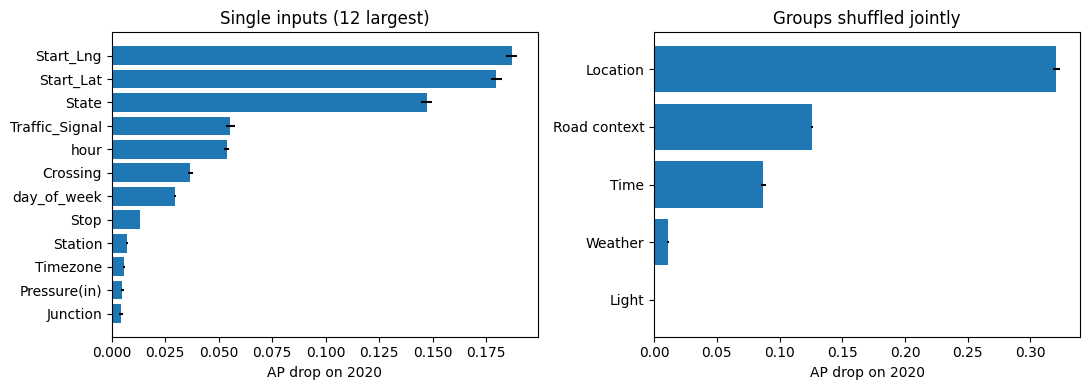

In [20]:
with threadpool_limits(limits=4):
    single = permutation_importance(boosting, X["validation"], y["validation"],
        scoring="average_precision", n_repeats=5, random_state=SEED)
single_importance = pd.DataFrame({"Input": X["validation"].columns,
    "AP drop": single.importances_mean, "Std": single.importances_std}).sort_values("AP drop", ascending=False)
input_group_columns = {"Time": ["hour", "day_of_week", "month", "weekend"],
    "Location": ["Start_Lat", "Start_Lng", "State", "Timezone"], "Road context": ROAD,
    "Light": LIGHT, "Weather": WNUM + WCAT}
reference_ap = average_precision_score(y["validation"], predictions["validation"]["Boosting"])
rng = np.random.RandomState(SEED)
group_rows = []
with threadpool_limits(limits=4):
    for group, columns in input_group_columns.items():
        columns = [c for c in columns if c in X["validation"]]
        drops = []
        for _ in range(5):
            order = rng.permutation(len(X["validation"]))
            shuffled = X["validation"].copy()
            for column in columns:
                shuffled[column] = shuffled[column].iloc[order].set_axis(shuffled.index)
            drops.append(reference_ap - average_precision_score(
                y["validation"], boosting.predict_proba(shuffled)[:, 1]))
        group_rows.append({"Group": group, "Inputs": len(columns),
            "AP drop": np.mean(drops), "Std": np.std(drops)})
group_importance = pd.DataFrame(group_rows).sort_values("AP drop", ascending=False)
display(group_importance.round(4))
single_importance.to_csv(REPORTS / "permutation_inputs.csv", index=False)
group_importance.to_csv(REPORTS / "permutation_groups.csv", index=False)
top_inputs = single_importance.head(12).iloc[::-1]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].barh(top_inputs.Input, top_inputs["AP drop"], xerr=top_inputs.Std)
axes[0].set(xlabel="AP drop on 2020", title="Single inputs (12 largest)")
groups_plot = group_importance.iloc[::-1]
axes[1].barh(groups_plot.Group, groups_plot["AP drop"], xerr=groups_plot.Std)
axes[1].set(xlabel="AP drop on 2020", title="Groups shuffled jointly")
plt.tight_layout()
plt.savefig(FIGURES / "05_importance.png")
plt.show()

These drops describe what the fitted model uses to rank 2020 accidents. They
are not causal effects: an input can matter because it correlates with how
accidents were recorded, and a low score does not prove that a factor has no
influence on traffic. A group's drop can exceed those of its single inputs,
because its inputs can no longer stand in for one another. The ranking is measured on validation and was not used to
select inputs.

## 4. Evaluation

### 4.1 Examine later periods with the fixed models

We apply the fitted models and unchanged preparations to 2021 and the
available part of 2022. We keep the table compact and compare AP with the
prevalence reference, since the positive share changes between years.

In [21]:
with threadpool_limits(limits=4):
    for split in ["test", "stress"]:
        predictions[split]["Boosting"] = boosting.predict_proba(X[split])[:, 1]
        predictions[split]["Forest"] = predict_forest(split)
        predictions[split]["Logistic"] = predict_logistic(split)
        for name, values in predictions[split].items():
            score_rows.append({"Period": split, "Model": name,
                **evaluate(y[split], values, thresholds[name], raw_clean[split]._priority.to_numpy())})
scores = pd.DataFrame(score_rows)
scores.to_csv(REPORTS / "model_scores.csv", index=False)
compact_scores = scores[scores.Period.isin(["test", "stress"])][
    ["Period", "Model", "AP", "ROC-AUC", "Precision", "Recall", "F1"]].copy()
compact_scores["Period"] = compact_scores.Period.map(period_names)
display(compact_scores.round(3))

,Period,Model,AP,ROC-AUC,Precision,Recall,F1
4,2021 (historical),Constant,0.343,0.500,0.343,1.000,0.511
5,2021 (historical),Boosting,0.752,0.867,0.648,0.798,0.715
6,2021 (historical),Forest,0.711,0.831,0.598,0.776,0.676
7,2021 (historical),Logistic,0.564,0.733,0.467,0.822,0.596
8,2022 to Sep 8,Constant,0.347,0.500,0.347,1.000,0.515
9,2022 to Sep 8,Boosting,0.754,0.864,0.642,0.810,0.716
10,2022 to Sep 8,Forest,0.701,0.823,0.589,0.783,0.673
11,2022 to Sep 8,Logistic,0.571,0.733,0.467,0.835,0.599


Boosting remains ahead of the selected forest and the logistic regression
on these historical periods.
Similar scores across years are encouraging for this scope, but changes in
labels and incomplete coverage limit the interpretation. These years had
already been explored in the project; a new confirmation would require a
later independent period.

### 4.2 Visualise precision, recall and temporal ranking

The precision-recall curve shows the tradeoff across thresholds. Its reference
line is the positive share of the evaluated sample. A second figure compares
AP across years, with the baseline included to show changing prevalence.

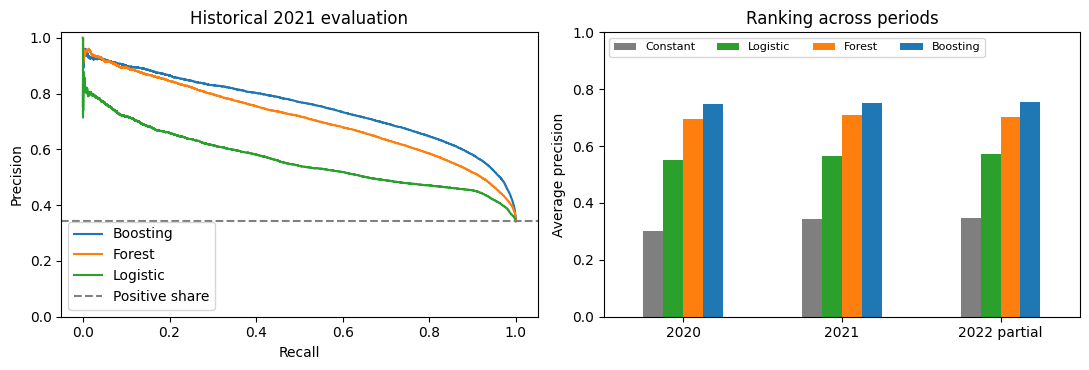

In [22]:
model_colors = {"Constant": "tab:gray", "Logistic": "tab:green", "Forest": "tab:orange", "Boosting": "tab:blue"}
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for name in ["Boosting", "Forest", "Logistic"]:
    precision, recall, _ = precision_recall_curve(y["test"], predictions["test"][name])
    axes[0].plot(recall, precision, label=name, color=model_colors[name])
axes[0].axhline(y["test"].mean(), color="gray", linestyle="--", label="Positive share")
axes[0].set(xlabel="Recall", ylabel="Precision", title="Historical 2021 evaluation", ylim=(0, 1.02))
axes[0].legend()
ranking = scores.pivot(index="Period", columns="Model", values="AP").reindex(["validation", "test", "stress"])
ranking.index = ["2020", "2021", "2022 partial"]
ranking[["Constant", "Logistic", "Forest", "Boosting"]].plot.bar(ax=axes[1], rot=0, color=model_colors)
axes[1].set(ylabel="Average precision", xlabel="", title="Ranking across periods", ylim=(0, 1))
axes[1].legend(loc="upper left", ncol=4, fontsize=8)
plt.tight_layout()
plt.savefig(FIGURES / "06_evaluation.png")
plt.show()

Better ranking does not remove the precision-recall tradeoff. A more permissive
threshold finds more positives but also creates more false alerts. AP and
ROC-AUC describe ranking; they do not show that the numerical scores are
calibrated probabilities.

### 4.3 Understand the remaining mistakes

We inspect the 2021 confusion matrix at the fixed F1 threshold and check
recall separately for Severity 3 and 4. This avoids letting the common level 3
hide the rare level 4. These diagnostics do not select a new model or threshold.

In [23]:
positive_test = predictions["test"]["Boosting"] >= thresholds["Boosting"]
matrix = confusion_matrix(y["test"], positive_test, labels=[0, 1])
display(pd.DataFrame(matrix, index=["Actual low impact", "Actual high impact"],
    columns=["Predicted low impact", "Predicted high impact"]))
severity_diagnostics = []
for level in [3, 4]:
    mask = raw_clean["test"].Severity.eq(level).to_numpy()
    severity_diagnostics.append({"Severity": level, "Events": int(mask.sum()),
        "Recall (%)": round(100 * positive_test[mask].mean(), 1)})
display(pd.DataFrame(severity_diagnostics))
test_boosting = scores[(scores.Period == "test") & (scores.Model == "Boosting")].iloc[0]
display(Markdown(f"At the fixed threshold, boosting finds about **{100*test_boosting.Recall:.0f}%** "
    f"of high-impact events. About **{100*test_boosting.Precision:.0f}%** of its positive predictions "
    "are actually high-impact records. Both missed events and false alerts remain."))

,Predicted low impact,Predicted high impact
Actual low impact,50894,14832
Actual high impact,6923,27350


,Severity,Events,Recall (%)
0,3,33452,79.8
1,4,821,78.4


At the fixed threshold, boosting finds about **80%** of high-impact events. About **65%** of its positive predictions are actually high-impact records. Both missed events and false alerts remain.

The overall binary metrics are mostly driven by Severity 3. The smaller count
for level 4 makes its recall less secure as a general conclusion. The matrix
describes errors under our study labels, not injury outcomes or operational
intervention costs.

### 4.4 Look for patterns in errors without changing the model

As a first descriptive analysis, we group 2021 by start-hour range. We show
both missed-positive and false-positive rates with their denominators. A
difference can reflect population composition; it is not evidence of causation.

In [24]:
errors = pd.DataFrame({"Hour group": pd.cut(raw_clean["test"]._t.dt.hour,
    bins=[-1, 5, 11, 17, 23], labels=["00-05", "06-11", "12-17", "18-23"]),
    "Actual": y["test"], "Predicted": positive_test})
error_rows = []
for group, frame in errors.groupby("Hour group", observed=True):
    actual = frame.Actual.eq(1)
    negatives = ~actual
    error_rows.append({"Start hour": str(group), "Events": len(frame),
        "Positives": int(actual.sum()), "Negatives": int(negatives.sum()),
        "Missed positives (%)": 100 * (~frame.loc[actual, "Predicted"]).mean(),
        "False positives (%)": 100 * frame.loc[negatives, "Predicted"].mean()})
error_table = pd.DataFrame(error_rows)
display(error_table.round(1))
error_table.to_csv(REPORTS / "errors_by_hour.csv", index=False)

,Start hour,Events,Positives,Negatives,Missed positives (%),False positives (%)
0,00-05,10439,2809,7630,24.5,25.7
1,06-11,45973,11378,34595,29.3,20.1
2,12-17,29611,13467,16144,15.0,25.7
3,18-23,13976,6619,7357,13.4,24.1


In this sample, the missed-positive rate is higher in the morning than in the
evening. This gives us a concrete subgroup to investigate further. The two
error types have different denominators, and population differences can
contribute to the pattern. We keep the model fixed rather than tuning it on
this historical evaluation.

### 4.5 Distinguish a classification threshold from an alert budget

Selecting only the highest 10% of scores is a different decision from the
F1 threshold. We report the main model under both policies. Ties in the budget
are broken using event priorities independent of the labels. The budget is
retrospective, not a validated streaming alert service.

In [25]:
policies = pd.DataFrame([
    {"Policy": "Validation-selected F1 threshold", "Precision (%)": 100 * test_boosting.Precision,
     "Recall (%)": 100 * test_boosting.Recall},
    {"Policy": "Highest 10% of scores", "Precision (%)": 100 * test_boosting["Precision top 10%"],
     "Recall (%)": 100 * test_boosting["Recall top 10%"]}])
display(policies.round(1))

,Policy,Precision (%),Recall (%)
0,Validation-selected F1 threshold,64.8,79.8
1,Highest 10% of scores,84.7,24.7


Concentrating on fewer events can raise precision while finding a smaller
share of all positives. These recalls should never be presented as the same
measure. A deployment policy would also need costs, publication times and
probability calibration, which are outside this study.

## 5. Conclusion

We bring the main observations together, keeping the numerical summary short.
The following paragraph uses the scores calculated in this execution.

In [26]:
partial_boosting = scores[(scores.Period == "stress") & (scores.Model == "Boosting")].iloc[0]
display(Markdown(f"Our selected boosting model reaches **AP {test_boosting.AP:.3f}** "
    f"in the historical 2021 evaluation and **{partial_boosting.AP:.3f}** in the available part of 2022. "
    "It improves on the selected forest, the logistic regression and the constant reference "
    "under the common protocol. "
    "The main choices are a larger training sample and a more capable boosting configuration; "
    "the weather category limit is a smaller refinement."))

Our selected boosting model reaches **AP 0.752** in the historical 2021 evaluation and **0.754** in the available part of 2022. It improves on the selected forest, the logistic regression and the constant reference under the common protocol. The main choices are a larger training sample and a more capable boosting configuration; the weather category limit is a smaller refinement.

Combining the approaches helped us understand that preprocessing and evaluation
belong together. Kamar's exploration and first models made the preparation
choices concrete. Yanis's event and temporal checks made the comparisons
easier to interpret. A higher score is meaningful only when we know its data,
permitted information and prediction time.

The model still makes mistakes. Results concern one provider, most positives
are level 3, and 2022 is incomplete. Weather observation times do not establish
publication times, and the update is a later prediction. We have not calibrated
the scores as probabilities or confirmed the model on a newly unseen period.
With more time, we would extend error analysis to locations, study calibration,
and evaluate on a later independent period.

## Appendix A. Full data dictionary

Each original column and each derived input is defined below. Expand a field
to see its type, unit, role, time reference and treatment. The same dictionary
is exported to `data/final_notebook/reports/data_dictionary.csv`. The expandable
entries use lightweight HTML, without an interactive plotting dependency.

In [27]:
from html import escape
entries = []
for row in dictionary.to_dict("records"):
    body = "".join(f"<dt><b>{escape(key)}</b></dt><dd>{escape(str(value))}</dd>"
        for key, value in row.items() if key not in ["Column", "Meaning"])
    entries.append(f"<details style='margin:6px 0'><summary><b>{escape(row['Column'])}</b>: "
        f"{escape(row['Meaning'])}</summary><dl>{body}</dl></details>")
display(HTML("".join(entries)))

The dictionary distinguishes excluded columns from fields used only for an
audit. The data's measurement units are kept explicit. The availability
descriptions are study assumptions where publication times are absent.

## Appendix B. Reproduction and consistency

We check periods, event uniqueness, input exclusions and fixed category rules.
Boosting must reproduce its recorded validation AP and threshold exactly: a
constant input such as Turning_Loop cannot be used by any split, so removing
it leaves the model unchanged. The forest is different. Its recorded result
used 34 inputs and training medians for wind chill; it now uses 33 inputs and
the wind chill option of 3.4. With one input fewer, the random feature subsets
at each split also differ. We therefore show the recorded and current forest
AP side by side instead of requiring them to match.
These are internal consistency checks, not independent validation of labels.
An approximate proximity diagnostic uses explicit nanosecond timestamps;
it never removes nearby events or changes the model.

In [28]:
checks = {}
years = {"train": {2016, 2017, 2018, 2019}, "validation": {2020}, "test": {2021}, "stress": {2022}}
for split, frame in raw_clean.items():
    checks[f"{split}: Source2, years and unique events"] = bool(frame.Source.eq("Source2").all()
        and set(frame._t.dt.year.unique()) <= years[split] and frame._event.is_unique)
    checks[f"{split}: 33 inputs, target excluded"] = X[split].shape[1] == 33 and not set(X[split]) & FORBIDDEN
    for column in category_prep.vocab:
        assert X[split][column].cat.categories.equals(X["train"][column].cat.categories)
for first, second in itertools.combinations(raw_clean, 2):
    checks[f"{first}/{second}: no temporal/event overlap"] = bool(
        raw_clean[first]._t.max() < raw_clean[second]._t.min()
        and not np.intersect1d(raw_clean[first]._event, raw_clean[second]._event).size)
checks["Expected sample sizes"] = [len(y[s]) for s in y] == [500000, 50000, 99999, 50000]
checks["Turning_Loop constant and excluded"] = bool(features["train"].Turning_Loop.eq(0).all()
    and all("Turning_Loop" not in X[s] and "Turning_Loop" not in forest_categories.columns for s in X))
checks["Complete original and derived dictionary"] = len(dictionary) == len(preview.columns) + 4
frozen = json.loads((COMPARISONS / "frozen_selection.json").read_text())
checks["Selection used validation only"] = frozen["test_used_for_selection"] is False
references = {r["family"]: r for r in frozen["selected"]}
actual = validation_scores[validation_scores.Model.eq("Boosting")].iloc[0]
checks["Boosting: recorded validation reproduced"] = bool(
    np.isclose(actual.AP, references["hgb"]["ap"], atol=1e-8, rtol=0)
    and np.isclose(thresholds["Boosting"], references["hgb"]["threshold"], atol=1e-8, rtol=0))
forest_validation = validation_scores[validation_scores.Model.eq("Forest")].iloc[0]
display(pd.DataFrame({"Recorded forest (34 inputs, median only)": [references["rf"]["ap"]],
    "Current forest": [forest_validation.AP]}, index=["Validation AP"]).round(4))
probe = raw_clean["train"].iloc[:50000].copy()
ns_keys = nearby_keys(probe.assign(Start_Time=probe._t.astype("datetime64[ns]")))
us_keys = nearby_keys(probe.assign(Start_Time=probe._t.astype("datetime64[us]")))
checks["Proximity independent of timestamp unit"] = bool(np.array_equal(ns_keys, us_keys))
check_table = pd.DataFrame({"Check": checks.keys(), "Passed": checks.values()})
check_table.to_csv(REPORTS / "consistency_checks.csv", index=False)
assert check_table.Passed.all(), check_table.loc[~check_table.Passed]
display(Markdown("The period, preparation and reproduction checks passed. Full details are saved in the reports folder."))

,"Recorded forest (34 inputs, median only)",Current forest
Validation AP,0.6961,0.6965


The period, preparation and reproduction checks passed. Full details are saved in the reports folder.

The notebook uses `traffic_impact/` modules, the requirements files and the
small common-comparison tables under `results/final_notebook_comparison/`.
Keep that structure when reproducing it. Put the CSV in `data/` or set
CSV_PATH, then run all cells in order. Caches, generated reports and figures
are stored in `data/final_notebook/` and can be regenerated. Do not submit the
raw CSV, caches or fitted models.

Internal checks support reproducibility within this setup; they do not prove
the absence of every possible bias. The complete comparison exports remain
available for inspecting the wider search and its limits.